# Predicting Crash Severity & Prioritizing Bridgeport Hotspots
**Jan Salafia, Sean Salafia — Machine Learning final project**

**Data:** Connecticut Crash Data Repository (CTCDR), MMUCC crash-level export (`data/export_94993_0.csv`):
31,751 police-reported crashes in **Bridgeport** from January 2021 through November 2026 (nearly six years).
The export's vehicle (`_1`) and person (`_2`) files are not used — this analysis uses one row per crash.

**Research question:** Can crash-report features help predict whether a crash is severe (fatal or suspected serious injury),
and do hotspots ranked by the model's predicted severe-crash burden differ from hotspots ranked by crash count?

**Notebook outline**
1. Setup & configuration
2. Load data
3. Preprocessing, severity score and target
4. Exploratory data analysis
5. Severity predictor: baseline vs. logistic regression vs. random forest
6. Historical hotspots: DBSCAN clusters, ranked by observed KABCO score, severe crashes, and crash count
7. Compare held-out ML-predicted severity burden with crash count; examine shared conditions
8. Summary & limitations

## 1. Setup & configuration

In [18]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RNG = 42

# ---------------- CONFIG ----------------
DATA_FILE = "data/export_94993_0.csv"   # Crash data
TOWNS = ["Bridgeport"]                  # Bridgeport only for now

# Simple severity score (KABCO): higher = more severe. Severe = K (fatal) or A (suspected serious injury).
SEVERITY_SCORE = {"K": 5, "A": 4, "B": 3, "C": 2, "O": 1}

COLS = {
    "crash_id": "CrashId",
    "date":     "Date Of Crash",
    "time":     "Time of Crash",
    "town":     "Town Name",
    "lat":      "Latitude",
    "lon":      "Longitude",
    "severity": "Most Severe Injury Text Format",
}

# Model features: conditions recorded on the crash report. Nothing that is only known after the outcome
# (injury counts, "Crash Severity", ambulance/transport) is included — that would leak the answer.
CAT_FEATURES = ["Manner of Crash / Collision Impact Text Format", "First Harmful Event Text Format",
                "Light Condition Text Format", "Weather Condition Text Format", "Road Surface Condition Text Format",
                "Route Class Text Format", "Type of Intersection Text Format"]
NUM_FEATURES = ["Number Of Motor Vehicles", "Number Of Non-Motorist"]
TIME_FEATURES = ["hour", "dow", "month"]   # created from the crash date/time below

# Hotspot clustering
# Bridgeport is dense: at 100 m DBSCAN chains most of the city into one cluster. 25 m / 25 crashes gives
# intersection- or short-segment-sized hotspots (largest spans roughly 300 m).
EPS_METERS = 25         # crashes within this distance chain into one hotspot
MIN_CRASHES = 25        # minimum crashes to call a cluster a hotspot
TOP_N = 25              # size of the "top list" used when comparing rankings

## 2. Load data

In [19]:
raw = pd.read_csv(DATA_FILE, skiprows=1, encoding="cp1252", low_memory=False)
print(f"Loaded {DATA_FILE}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

missing = [c for c in list(COLS.values()) + CAT_FEATURES + NUM_FEATURES if c not in raw.columns]
print("Columns not found (edit COLS / features above):", missing)
raw[list(COLS.values())].head()

Loaded data/export_94993_0.csv: 31,751 rows x 103 columns
Columns not found (edit COLS / features above): []


,CrashId,Date Of Crash,Time of Crash,Town Name,Latitude,Longitude,Most Severe Injury Text Format
0,776559,2021-01-01,00:11:00,Bridgeport,41.171045,-73.191605,Possible Injury (C)
1,776560,2021-01-01,18:48:00,Bridgeport,41.188309,-73.201132,No Apparent Injury (O)
2,776561,2021-01-01,22:15:00,Bridgeport,41.198582,-73.201579,No Apparent Injury (O)
3,776562,2021-01-02,03:11:00,Bridgeport,41.171402,-73.202916,No Apparent Injury (O)
4,776563,2021-01-02,06:34:00,Bridgeport,41.186612,-73.170140,Possible Injury (C)


## 3. Preprocessing
- Rename the key columns, remove duplicate crash records, report missing values
- Parse the crash date and time; keep Bridgeport crashes
- Convert severity text to KABCO letters → severity score (K=5 … O=1) and binary target `severe` (K or A)
- Coordinates outside the Bridgeport area are set to missing; those records remain in the crash-level model but are not assigned to a hotspot
- Missing categorical values become `"Missing"`, number of non-motorists missing → 0, missing numbers get the median (done inside the model pipeline)

In [20]:
def parse_kabco(s):
    """Map CTCDR severity text to K/A/B/C/O. Handles 'K - Fatal Injury', 'K', or plain descriptions."""
    if pd.isna(s): return np.nan
    t = str(s).strip().upper()
    m = re.match(r"^([KABCO])\b", t)
    if m: return m.group(1)
    if "FATAL" in t: return "K"
    if "SERIOUS" in t: return "A"
    if "MINOR" in t: return "B"
    if "POSSIBLE" in t: return "C"
    if "NO APPARENT" in t or "NO INJURY" in t or "PROPERTY" in t: return "O"
    return np.nan

df = raw.rename(columns={v: k for k, v in COLS.items()})
print(f"Duplicate crash IDs removed: {df.crash_id.duplicated().sum():,}")
df = df.drop_duplicates(subset="crash_id")

print("\nMissing values (% of rows):")
print((df[list(COLS) + [c for c in CAT_FEATURES + NUM_FEATURES if c in df]].isna().mean() * 100).round(1))

# Date / time
if "datetime" in df:
    df["dt"] = pd.to_datetime(df["datetime"], errors="coerce")
elif "time" in df:
    df["dt"] = pd.to_datetime(df["date"].astype(str) + " " + df["time"].astype(str), errors="coerce")
else:
    df["dt"] = pd.to_datetime(df["date"], errors="coerce")

df["town"] = df.town.astype(str).str.strip().str.title()
df["kabco"] = df.severity.map(parse_kabco)
print("\nUnparsed severity values:", df.loc[df.kabco.isna(), "severity"].value_counts(dropna=False).head(8).to_dict())

steps = {"after duplicates": len(df)}
df = df[df.dt.notna()];                         steps["valid date"] = len(df)
df = df[df.town.isin(TOWNS)];                   steps["Bridgeport"] = len(df)
df = df[df.kabco.notna()];                      steps["severity known"] = len(df)
print(pd.Series(steps).to_frame("rows remaining"))

Duplicate crash IDs removed: 0

Missing values (% of rows):
crash_id                                          0.0
date                                              0.0
time                                              0.0
town                                              0.0
lat                                               0.0
lon                                               0.0
severity                                          0.0
Manner of Crash / Collision Impact Text Format    0.0
First Harmful Event Text Format                   0.0
Light Condition Text Format                       0.0
Weather Condition Text Format                     0.0
Road Surface Condition Text Format                0.0
Route Class Text Format                           2.7
Type of Intersection Text Format                  0.0
Number Of Motor Vehicles                          0.0
Number Of Non-Motorist                            0.0
dtype: float64

Unparsed severity values: {}
                  rows remainin

In [21]:
# Coordinates: keep only points inside a Bridgeport-area bounding box
df["lat"] = pd.to_numeric(df.lat, errors="coerce")
df["lon"] = pd.to_numeric(df.lon, errors="coerce")
bad_xy = ~(df.lat.between(41.10, 41.25) & df.lon.between(-73.27, -73.12))
df.loc[bad_xy, ["lat", "lon"]] = np.nan
print(f"Missing/invalid coordinates: {df.lat.isna().mean():.1%}")

# Target and severity score
df["sev_score"] = df.kabco.map(SEVERITY_SCORE)
df["severe"] = df.kabco.isin(["K", "A"]).astype(int)

# Time features
df["year"] = df.dt.dt.year
df["hour"] = df.dt.dt.hour
df["dow"] = df.dt.dt.dayofweek      # 0 = Monday
df["month"] = df.dt.dt.month

df["Number Of Non-Motorist"] = df["Number Of Non-Motorist"].fillna(0)

# Categorical features: consistent text, missing -> "Missing"
for c in CAT_FEATURES:
    df[c] = df[c].fillna("Missing").astype(str).str.strip()

df = df.reset_index(drop=True)
print(f"Final rows: {len(df):,}  |  years {df.year.min()}–{df.year.max()}  |  severe (K+A) share: {df.severe.mean():.2%}")

Missing/invalid coordinates: 0.0%
Final rows: 31,751  |  years 2021–2026  |  severe (K+A) share: 1.55%


## 4. Exploratory data analysis

       crashes   share
kabco                 
K           44  0.0014
A          448  0.0141
B         3965  0.1249
C         4930  0.1553
O        22364  0.7044


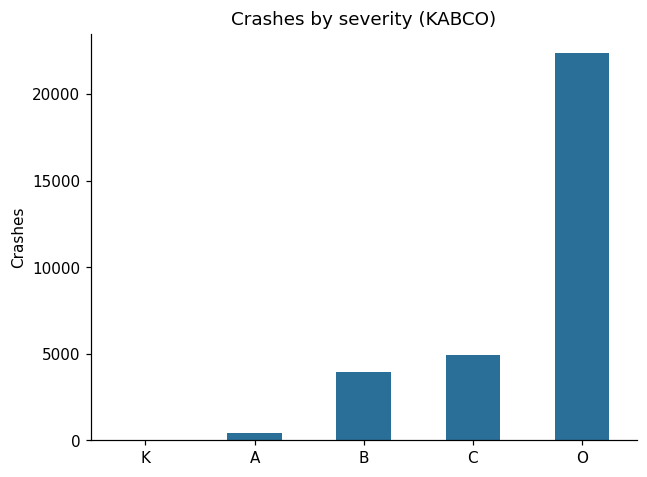

In [22]:
counts = df.kabco.value_counts().reindex(list("KABCO"))
print(counts.to_frame("crashes").assign(share=(counts / counts.sum()).round(4)))

ax = counts.plot(kind="bar", color="#2a6f97", rot=0)
ax.set(title="Crashes by severity (KABCO)", xlabel="", ylabel="Crashes"); plt.show()

Only 492 of 31,751 crashes (1.55%) are severe, so this is an **imbalanced** classification problem. Accuracy can be misleading; the model comparison emphasizes recall, F1, ROC-AUC, and especially PR-AUC against the 2.1% severe rate in the test set.

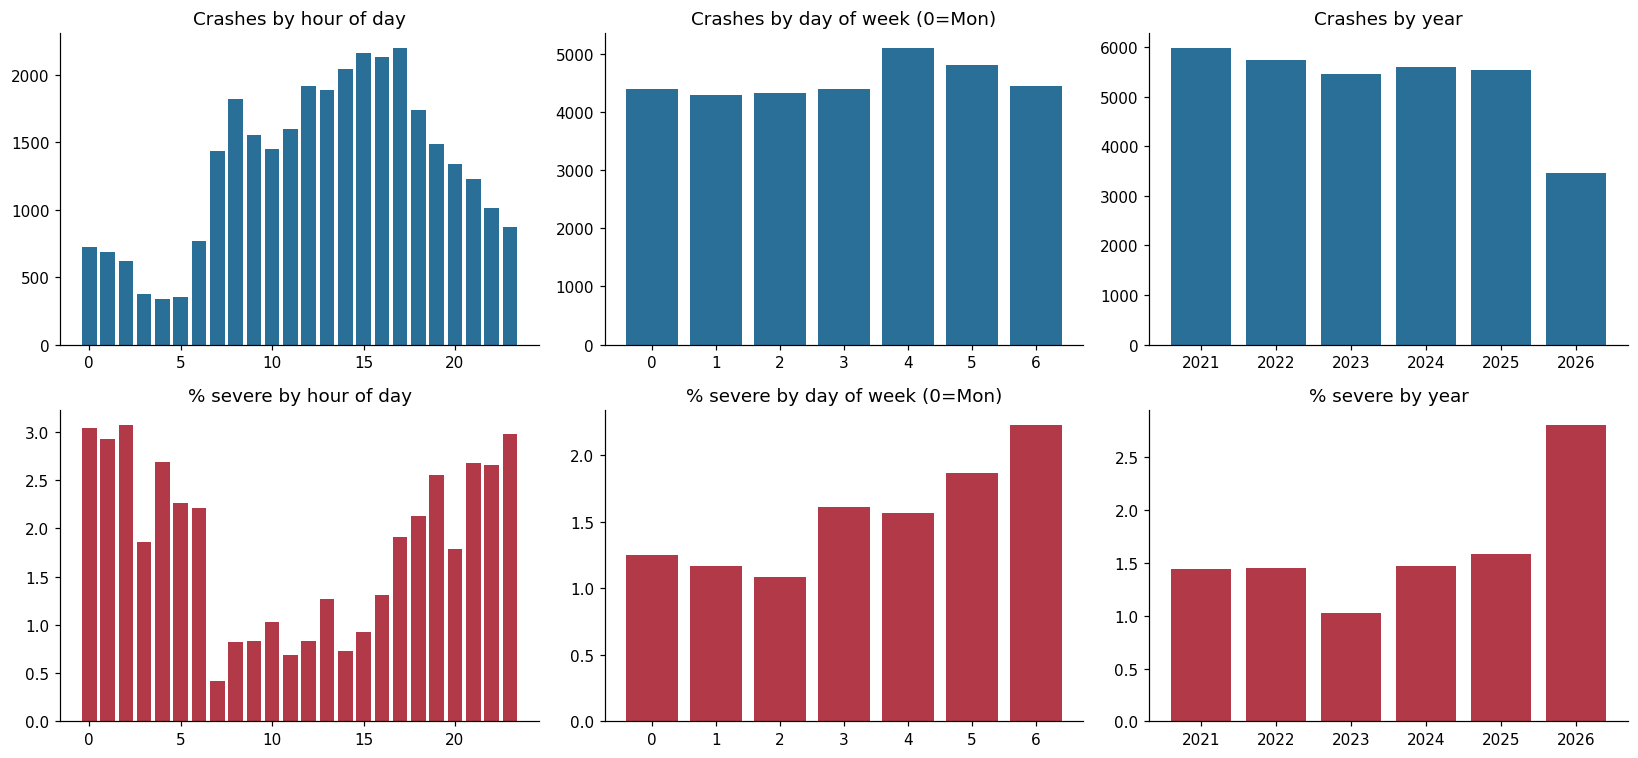

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, (col, ttl) in enumerate([("hour", "hour of day"), ("dow", "day of week (0=Mon)"), ("year", "year")]):
    g = df.groupby(col).severe.agg(["size", "mean"])
    axes[0, j].bar(g.index, g["size"], color="#2a6f97"); axes[0, j].set_title(f"Crashes by {ttl}")
    axes[1, j].bar(g.index, g["mean"] * 100, color="#b23a48"); axes[1, j].set_title(f"% severe by {ttl}")
plt.tight_layout(); plt.show()

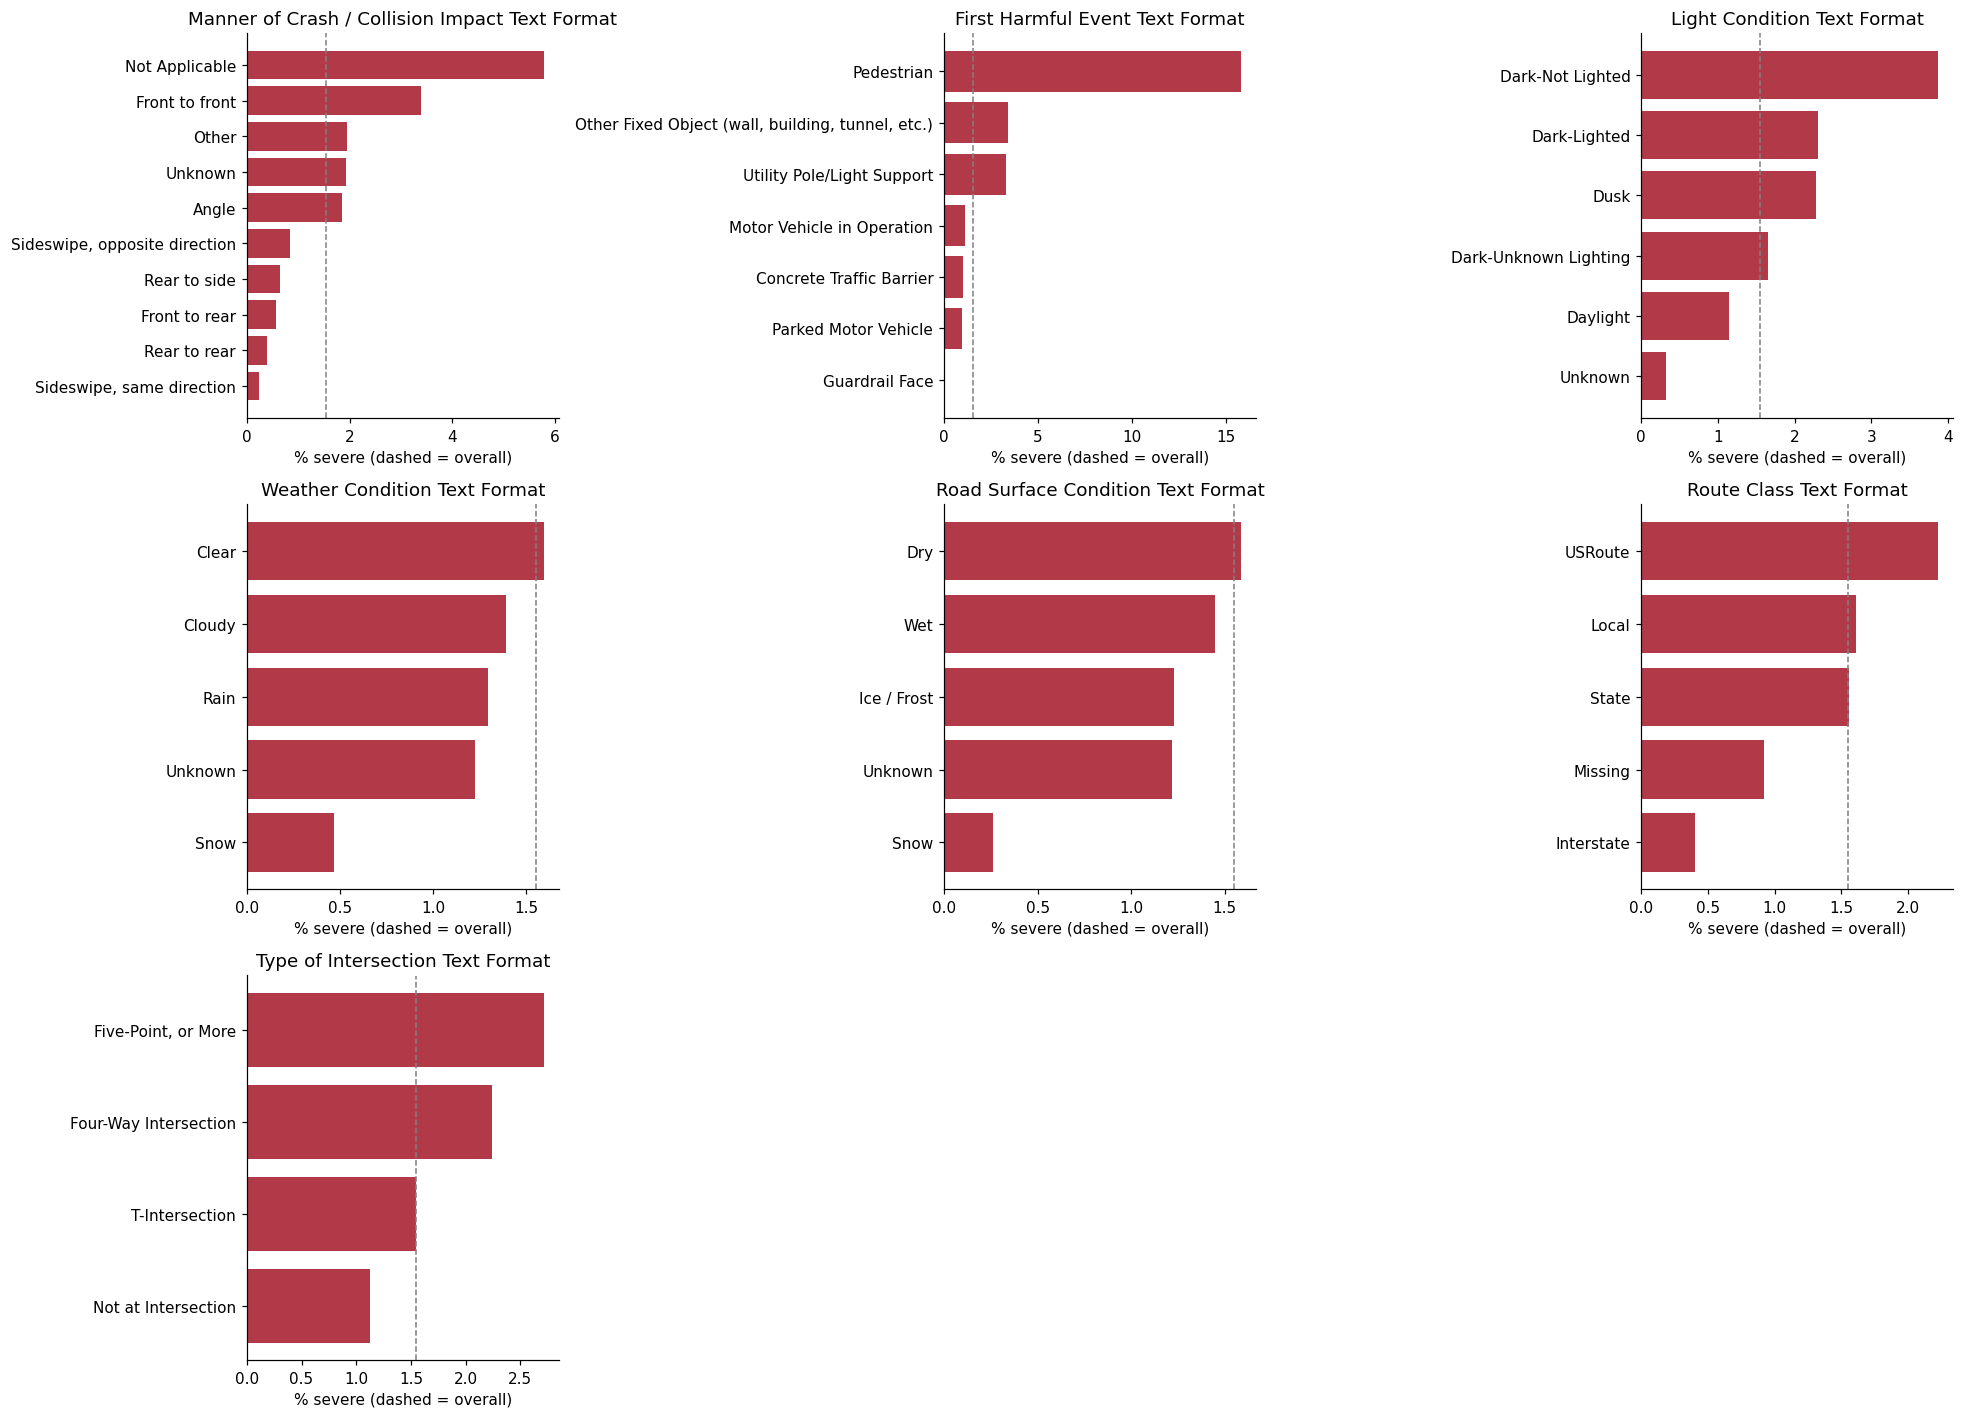

In [24]:
# Severe-crash rate by condition (categories with at least 200 crashes)
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.ravel(), CAT_FEATURES):
    g = df.groupby(col).severe.agg(["size", "mean"])
    g = g[g["size"] >= 200].sort_values("mean")
    ax.barh(g.index, g["mean"] * 100, color="#b23a48")
    ax.axvline(df.severe.mean() * 100, ls="--", c="grey", lw=1)
    ax.set_title(col); ax.set_xlabel("% severe (dashed = overall)")
for ax in axes.ravel()[len(CAT_FEATURES):]: ax.axis("off")
plt.tight_layout(); plt.show()

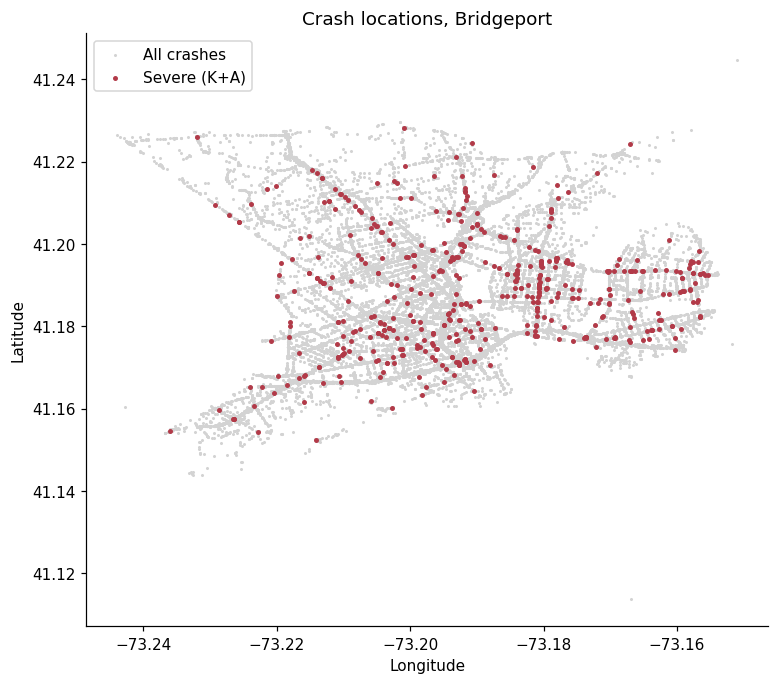

In [25]:
geo = df.dropna(subset=["lat", "lon"]).copy()
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(geo.lon, geo.lat, s=1, c="lightgrey", label="All crashes")
s = geo[geo.severe == 1]
ax.scatter(s.lon, s.lat, s=5, c="#b23a48", label="Severe (K+A)")
ax.set(title="Crash locations, Bridgeport", xlabel="Longitude", ylabel="Latitude"); ax.legend(); plt.show()

## 5. Crash-severity classifier
**Target:** `severe` = fatal (K) or suspected serious injury (A). **Features:** collision manner, first harmful event, lighting, weather, road surface, route/intersection type, vehicle and non-motorist counts, and hour, weekday, and month.

**Split by time:** train on 2021–2024 and test on the most recent two years (2025 and 2026 through November). This tests whether the classifier generalizes to later crash records; because some inputs describe the crash itself, it is not a pre-crash warning system.

**Models:** a baseline that always predicts "not severe", logistic regression, and random forest — both with
`class_weight="balanced"` so the rare severe class isn't ignored. For hotspot scoring, a separate random forest is fit on 2021–2023, sigmoid-calibrated on 2024, and scored on 2025–2026; its probabilities are summed within each hotspot.

In [26]:
test_years = [int(y) for y in sorted(df.year.unique())[-2:]]
train, test = df[~df.year.isin(test_years)], df[df.year.isin(test_years)]
FEATS = CAT_FEATURES + NUM_FEATURES + TIME_FEATURES
Xtr, ytr, Xte, yte = train[FEATS], train.severe, test[FEATS], test.severe
print(f"train {len(train):,} (before {test_years[0]}) | test {len(test):,} {test_years}")
print(f"severe rate  train {ytr.mean():.2%} | test {yte.mean():.2%}")

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT_FEATURES),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_FEATURES + TIME_FEATURES)])

models = {
    "Baseline (always not severe)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced",
                                            n_jobs=-1, random_state=RNG),
}
fitted, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("clf", model)]).fit(Xtr, ytr)
    fitted[name] = pipe
    pred, prob = pipe.predict(Xte), pipe.predict_proba(Xte)[:, 1]
    rows.append({"model": name, "precision": precision_score(yte, pred, zero_division=0),
                 "recall": recall_score(yte, pred), "F1": f1_score(yte, pred),
                 "ROC-AUC": roc_auc_score(yte, prob), "PR-AUC": average_precision_score(yte, prob)})
res = pd.DataFrame(rows).set_index("model")
print(f"\nPR-AUC of a random guess ≈ test severe rate = {yte.mean():.3f}")
res.round(3)

train 22,756 (before 2025) | test 8,995 [2025, 2026]
severe rate  train 1.35% | test 2.06%

PR-AUC of a random guess ≈ test severe rate = 0.021


,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,
Baseline (always not severe),0.000,0.000,0.000,0.500,0.021
Logistic regression,0.054,0.719,0.101,0.798,0.101
Random forest,0.084,0.395,0.138,0.792,0.136


===== Logistic regression =====
              precision    recall  f1-score   support

  Not severe       0.99      0.74      0.85      8810
      Severe       0.05      0.72      0.10       185

    accuracy                           0.74      8995
   macro avg       0.52      0.73      0.47      8995
weighted avg       0.97      0.74      0.83      8995

===== Random forest =====
              precision    recall  f1-score   support

  Not severe       0.99      0.91      0.95      8810
      Severe       0.08      0.39      0.14       185

    accuracy                           0.90      8995
   macro avg       0.54      0.65      0.54      8995
weighted avg       0.97      0.90      0.93      8995



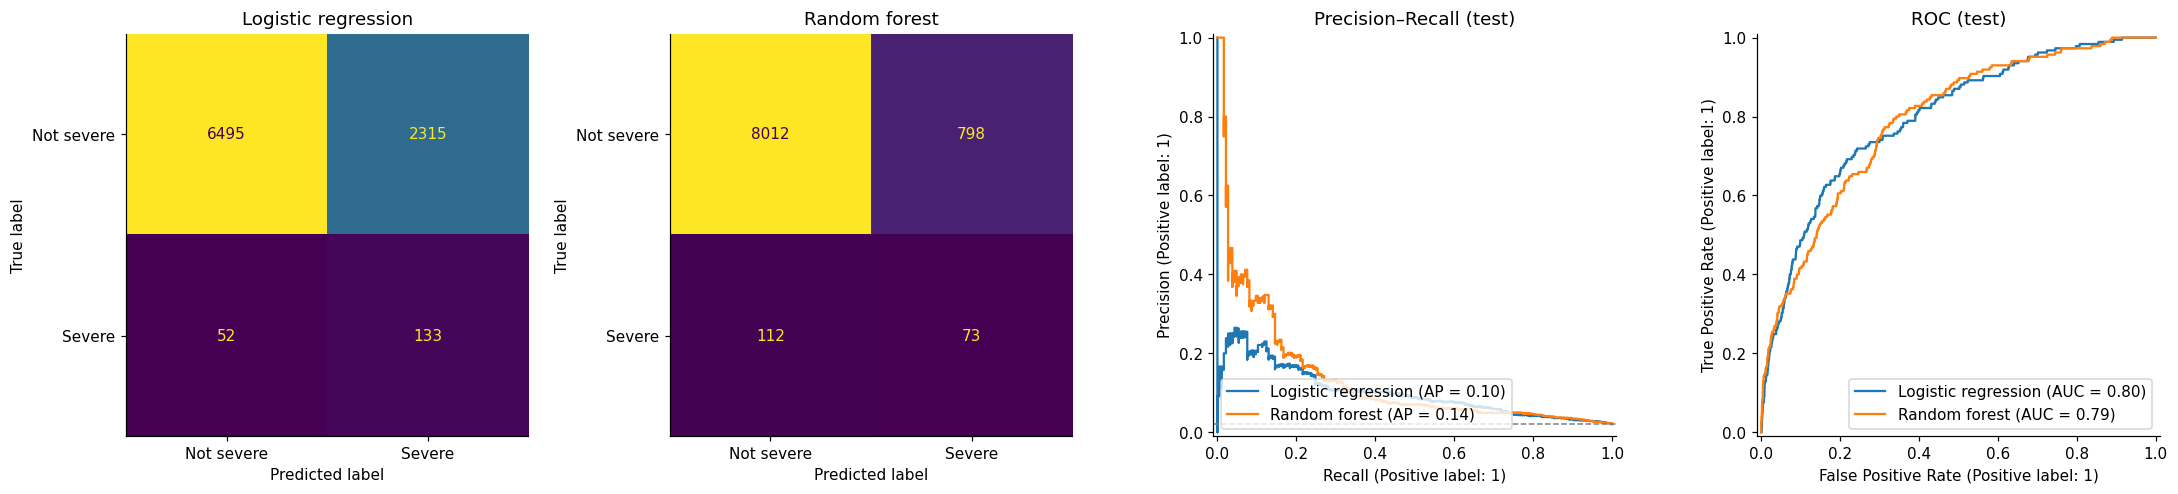

In [27]:
for name in ["Logistic regression", "Random forest"]:
    print(f"===== {name} =====")
    print(classification_report(yte, fitted[name].predict(Xte), target_names=["Not severe", "Severe"]))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes[:2], ["Logistic regression", "Random forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], Xte, yte, display_labels=["Not severe", "Severe"],
                                          ax=ax, colorbar=False)
    ax.set_title(name)
for name in ["Logistic regression", "Random forest"]:
    PrecisionRecallDisplay.from_estimator(fitted[name], Xte, yte, name=name, ax=axes[2])
    RocCurveDisplay.from_estimator(fitted[name], Xte, yte, name=name, ax=axes[3])
axes[2].axhline(yte.mean(), ls="--", c="grey", lw=1); axes[2].set_title("Precision–Recall (test)")
axes[3].set_title("ROC (test)")
plt.tight_layout(); plt.show()

### Which features matter?

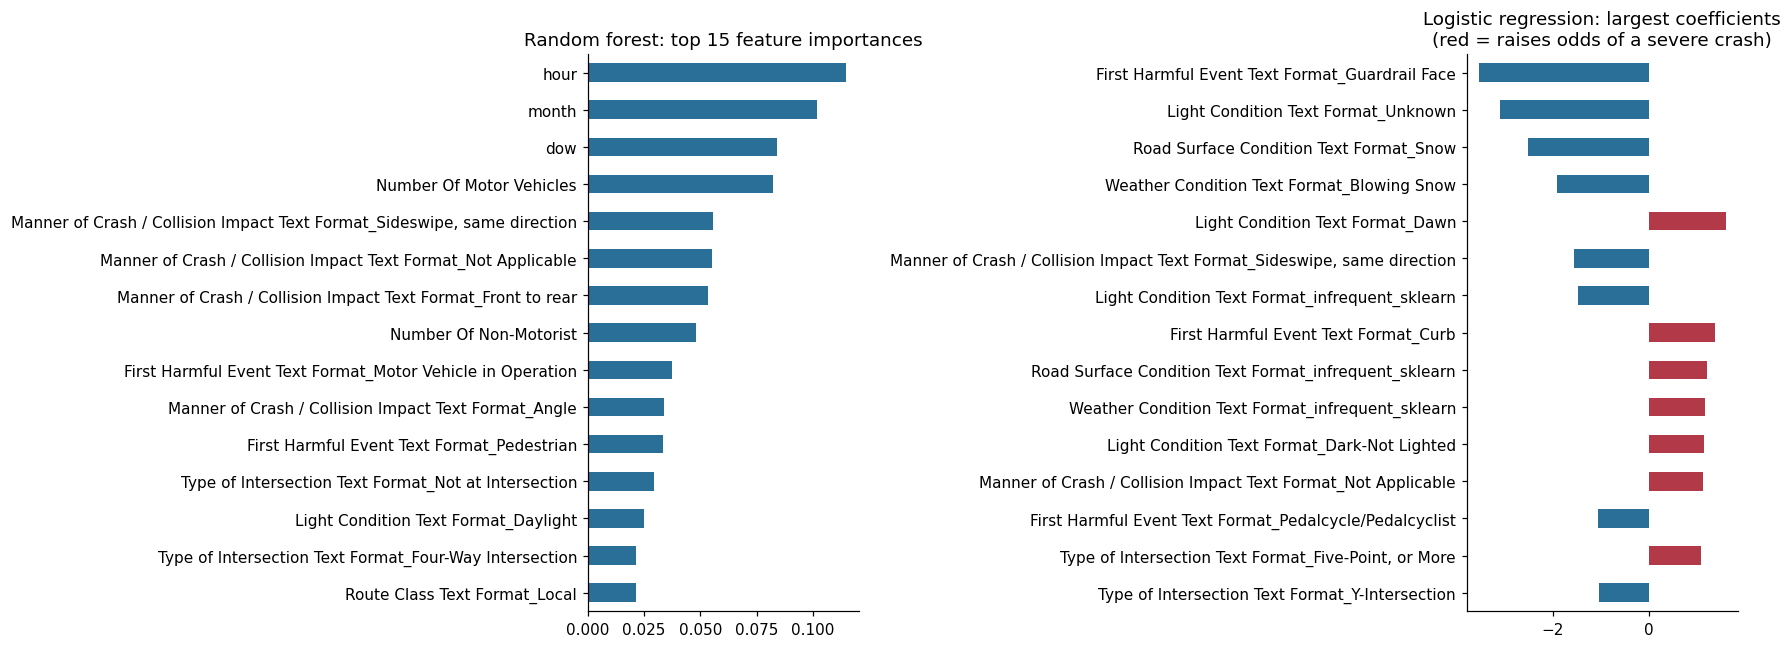

In [28]:
names = fitted["Random forest"].named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
rf_imp = pd.Series(fitted["Random forest"].named_steps["clf"].feature_importances_, index=names)
lr_coef = pd.Series(fitted["Logistic regression"].named_steps["clf"].coef_[0], index=names)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
rf_imp.sort_values().tail(15).plot(kind="barh", ax=axes[0], color="#2a6f97")
axes[0].set_title("Random forest: top 15 feature importances")
top = lr_coef.reindex(lr_coef.abs().sort_values().tail(15).index)
top.plot(kind="barh", ax=axes[1], color=np.where(top > 0, "#b23a48", "#2a6f97"))
axes[1].set_title("Logistic regression: largest coefficients\n(red = raises odds of a severe crash)")
plt.tight_layout(); plt.show()

## 6. Historical hotspots: cluster crashes, then compare observed rankings
Crash locations are converted to metres and grouped with **DBSCAN**: crashes within `EPS_METERS` of each other chain into
one cluster, and a cluster needs at least `MIN_CRASHES` crashes to count as a hotspot (isolated crashes are noise).
These full-period historical summaries are ranked three ways:
- **by crash count** — every crash counts equally
- **by observed total KABCO severity score** (K=5 … O=1) — a descriptive sum of known outcomes, not a model prediction
- **by observed number of severe (K+A) crashes** — where fatal and serious-injury crashes occurred

Because every crash adds at least 1 point, the observed KABCO score still grows with crash count. Section 7 separately compares the ML-based ranking: expected severe crashes from held-out model probabilities versus crash count over the same test period.

In [29]:
lat0 = geo.lat.mean()
XY = np.c_[geo.lon * 111_320 * np.cos(np.radians(lat0)), geo.lat * 110_540]   # approx. metres, fine at county scale
geo["hotspot"] = DBSCAN(eps=EPS_METERS, min_samples=MIN_CRASHES, n_jobs=-1).fit_predict(XY)

hot = geo[geo.hotspot >= 0].groupby("hotspot").agg(
    town=("town", lambda s: s.mode().iat[0]), lat=("lat", "mean"), lon=("lon", "mean"),
    crashes=("severe", "size"), severe=("severe", "sum"), fatal=("kabco", lambda s: (s == "K").sum()),
    severity_score=("sev_score", "sum")).reset_index()
hot["severe_rate"] = (hot.severe / hot.crashes).round(3)
ext = geo[geo.hotspot >= 0].groupby("hotspot").apply(lambda g: max(np.ptp(g.lat) * 110_540, np.ptp(g.lon) * 111_320 * np.cos(np.radians(lat0))))
hot["extent_m"] = hot.hotspot.map(ext).round(0)
hot["rank_count"] = hot.crashes.rank(ascending=False, method="min").astype(int)
hot["rank_severity"] = hot.severity_score.rank(ascending=False, method="min").astype(int)
hot["rank_severe"] = hot.severe.rank(ascending=False, method="min").astype(int)
hot = hot.sort_values("rank_severity")

print(f"{len(hot)} hotspots contain {(geo.hotspot >= 0).mean():.1%} of geocoded crashes; largest spans {hot.extent_m.max():.0f} m")
hot.head(15).round({"lat": 4, "lon": 4})

230 hotspots contain 47.1% of geocoded crashes; largest spans 382 m


,hotspot,town,lat,lon,crashes,severe,fatal,severity_score,severe_rate,extent_m,rank_count,rank_severity,rank_severe
18,18,Bridgeport,41.1810,-73.1945,575,4,1,837,0.007,314.0,1,1,6
31,31,Bridgeport,41.1934,-73.1687,350,9,0,570,0.026,382.0,3,2,1
15,15,Bridgeport,41.1747,-73.1949,392,0,0,525,0.000,373.0,2,3,128
62,62,Bridgeport,41.1855,-73.1921,259,4,0,407,0.015,139.0,4,4,6
6,6,Bridgeport,41.1966,-73.1936,232,7,2,344,0.030,183.0,7,5,2
41,41,Bridgeport,41.2031,-73.1888,236,1,0,335,0.004,98.0,6,6,66
99,99,Bridgeport,41.1829,-73.2064,237,2,1,326,0.008,175.0,5,7,26
36,36,Bridgeport,41.1969,-73.2002,215,5,0,303,0.023,132.0,8,8,3
169,169,Bridgeport,41.1773,-73.1950,201,1,0,291,0.005,131.0,9,9,66
40,40,Bridgeport,41.2074,-73.1929,178,2,0,262,0.011,122.0,10,10,26


                      Spearman vs. count rank  top-25 shared with count list
Total severity score                    0.971                             25
Severe (K+A) crashes                    0.300                              9


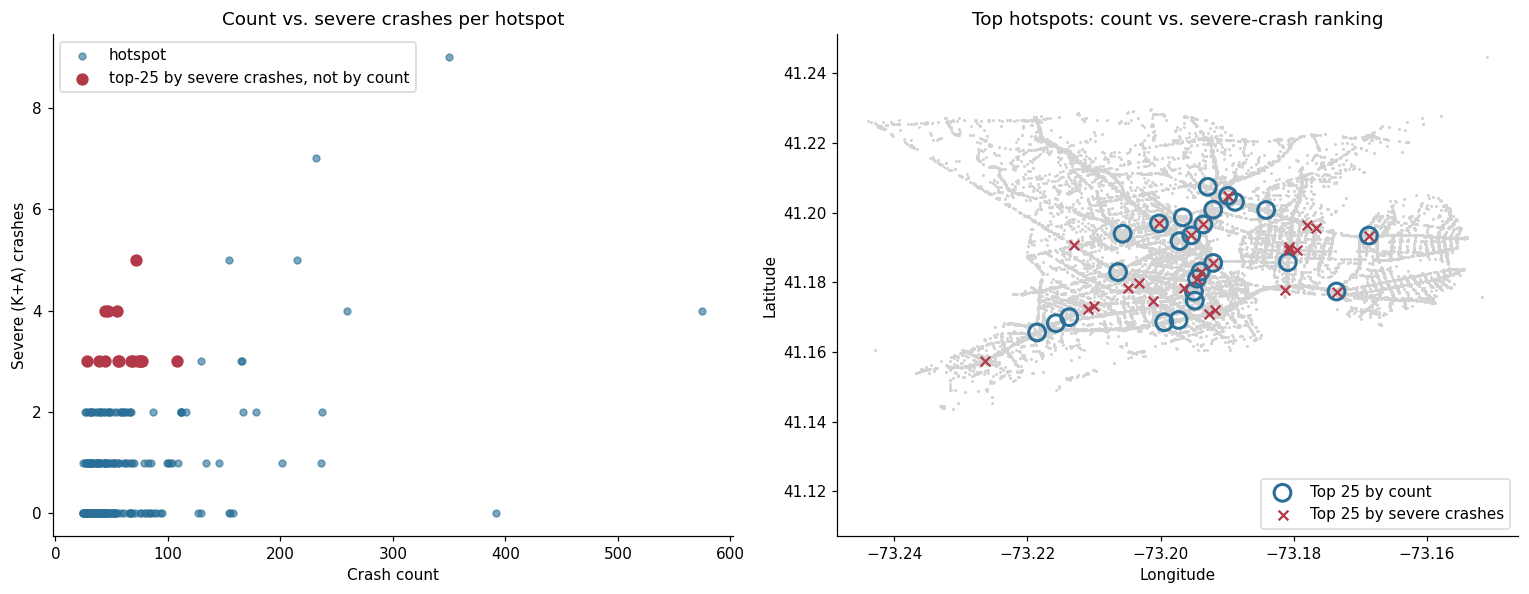

'Hidden' hotspots: top-25 by SEVERE CRASHES but not top-25 by COUNT (what a count-only ranking misses)


,hotspot,lat,lon,crashes,severe,fatal,severe_rate,rank_count,rank_severe
68,68,41.1891,-73.1807,72,5,0,0.069,53,3
3,3,41.1902,-73.1806,55,4,1,0.073,84,6
184,184,41.1796,-73.2032,47,4,0,0.085,110,6
135,135,41.1955,-73.1766,44,4,1,0.091,121,6
190,190,41.1719,-73.1918,108,3,0,0.028,29,11
168,168,41.1724,-73.2110,75,3,0,0.040,50,11
78,78,41.1707,-73.1928,77,3,1,0.039,47,11
51,51,41.1906,-73.2130,67,3,0,0.045,59,11
23,23,41.1965,-73.1780,69,3,0,0.043,56,11
32,32,41.1783,-73.1965,73,3,1,0.041,52,11


In [30]:
n = min(TOP_N, len(hot))
top_count = set(hot.sort_values("crashes", ascending=False).head(n).hotspot)
top_score = set(hot.sort_values("severity_score", ascending=False).head(n).hotspot)
top_sev = set(hot.sort_values(["severe", "severity_score"], ascending=False).head(n).hotspot)   # ties broken by score

print(pd.DataFrame({
    "Spearman vs. count rank": [spearmanr(hot.rank_count, hot.rank_severity)[0], spearmanr(hot.rank_count, hot.rank_severe)[0]],
    f"top-{n} shared with count list": [len(top_count & top_score), len(top_count & top_sev)],
}, index=["Total severity score", "Severe (K+A) crashes"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
hidden = hot[hot.hotspot.isin(top_sev - top_count)]
ax[0].scatter(hot.crashes, hot.severe, s=20, c="#2a6f97", alpha=.6, label="hotspot")
ax[0].scatter(hidden.crashes, hidden.severe, s=50, c="#b23a48", label=f"top-{n} by severe crashes, not by count")
ax[0].set(xlabel="Crash count", ylabel="Severe (K+A) crashes", title="Count vs. severe crashes per hotspot"); ax[0].legend()

ax[1].scatter(geo.lon, geo.lat, s=1, c="lightgrey")
tc, ts = hot[hot.hotspot.isin(top_count)], hot[hot.hotspot.isin(top_sev)]
ax[1].scatter(tc.lon, tc.lat, s=120, facecolors="none", edgecolors="#2a6f97", linewidths=2, label=f"Top {n} by count")
ax[1].scatter(ts.lon, ts.lat, s=40, c="#b23a48", marker="x", label=f"Top {n} by severe crashes")
ax[1].set(xlabel="Longitude", ylabel="Latitude", title="Top hotspots: count vs. severe-crash ranking"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"'Hidden' hotspots: top-{n} by SEVERE CRASHES but not top-{n} by COUNT (what a count-only ranking misses)")
hidden.sort_values(["severe", "severity_score"], ascending=False)[
    ["hotspot", "lat", "lon", "crashes", "severe", "fatal", "severe_rate", "rank_count", "rank_severe"]].round(4)

## 7. Interpreting hotspot patterns and the ML ranking
First, this section compares crash conditions in the 25 historical hotspots with the most observed severe (K+A) crashes against crashes elsewhere. **Lift** > 1 means a condition is more common in those hotspots. Interpret lift with counts and shares: a small category can have a large lift from very low outside volume.

These descriptive patterns are associations, **not causes**. Hotspot summaries are also affected by traffic volume, reporting, corridor size, and the 25 m clustering threshold.

The final comparison is the ML project’s main hotspot result. A Random Forest is fit on 2021–2023 crash records, calibrated on 2024, and evaluated on held-out 2025–2026 records. For each hotspot, **expected severe crashes** is the sum of its test crashes' calibrated severe probabilities. It is compared with the raw crash count for those exact same test-period crashes. Fractional expected counts are meaningful. This predicted burden is distinct from the full-period observed KABCO score in Section 6.

**Current results:**
- The ML and crash-count top 10 share **6 hotspots**. The ML-only locations are 99, 53, 25, and 11; the count-only locations are 9, 15, 72, and 169.
- Across scored test-period hotspot crashes, the model estimated 62.6 severe crashes versus 98 observed (mean predicted risk 1.51% vs. observed 2.36%). The model currently **underestimates absolute burden**, so interpret the score as a relative ranking, not an accurate count forecast.
- In the separate all-period descriptive analysis, the top 25 by observed severe crashes contain 96 severe crashes (about 19.5% of all severe crashes) and about 10.2% of geocoded crashes. Five-point-or-more intersections (lift 3.29), US routes (2.46), state routes (2.05), and front-to-rear impacts (1.50) are among the strongest over-represented conditions. These associations do not establish causes.
- The observed KABCO-score top 25 all overlap the crash-count top 25 (rank correlation 0.971), while the observed severe-crash-count top 25 share only 9 locations with the count top 25 (rank correlation 0.300). The model-based top-10 comparison is a separate, held-out-period analysis.

Top 25 hotspots: 3,232 crashes (10.2% of geocoded crashes)
They contain 96 severe crashes (19.5% of all severe crashes)
Severe-crash rate: top hotspots 2.97% vs. elsewhere 1.39%


,feature,value,share_in_top,share_elsewhere,lift,n_top
30,Type of Intersection Text Format,"Five-Point, or More",0.046,0.014,3.292,150
25,Route Class Text Format,USRoute,0.188,0.076,2.461,607
23,Route Class Text Format,State,0.408,0.199,2.054,1319
10,First Harmful Event Text Format,Guardrail Face,0.010,0.006,1.618,33
0,Manner of Crash / Collision Impact Text Format,Front to rear,0.416,0.277,1.502,1346
28,Type of Intersection Text Format,Four-Way Intersection,0.413,0.288,1.434,1334
8,First Harmful Event Text Format,Pedestrian,0.024,0.018,1.334,78
16,Light Condition Text Format,Dusk,0.011,0.010,1.095,34
7,First Harmful Event Text Format,Motor Vehicle in Operation,0.895,0.840,1.066,2893
14,Light Condition Text Format,Dark-Unknown Lighting,0.012,0.011,1.028,38


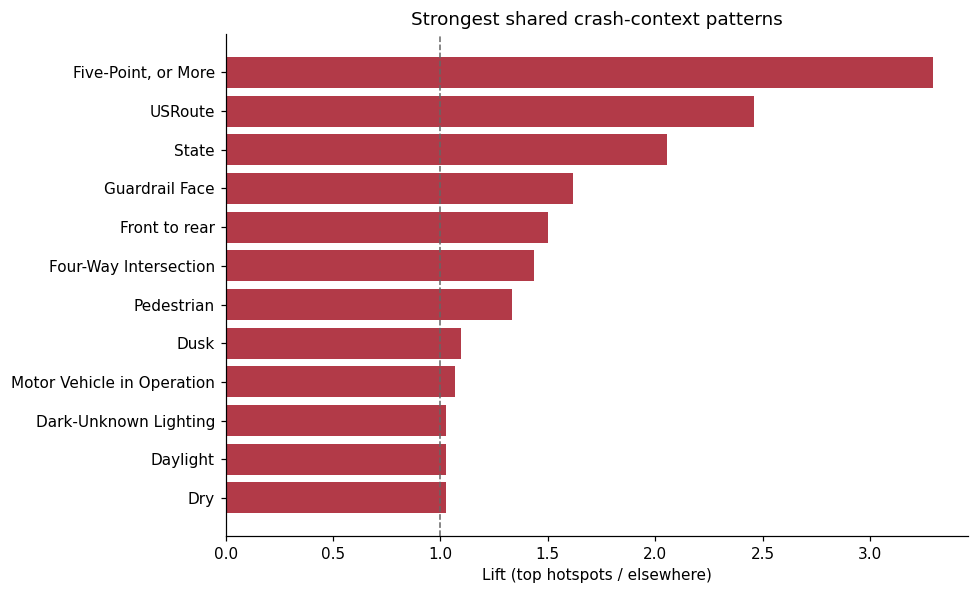

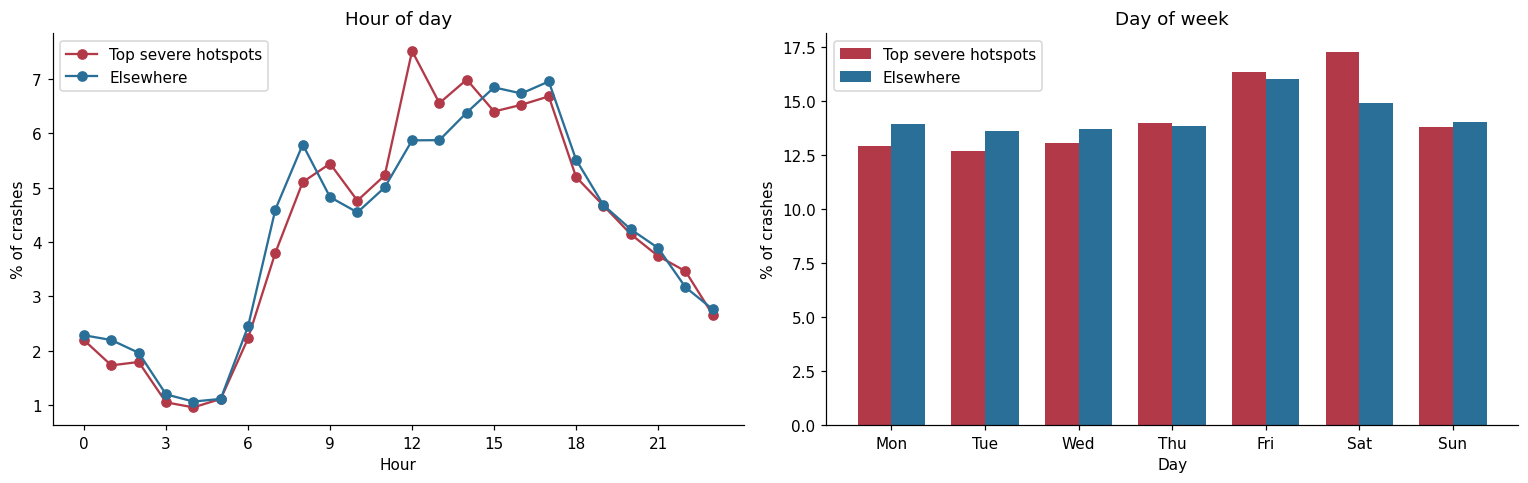

16 of the top-25 severe-crash hotspots are outside the top-25 by total crashes.


,hotspot,lat,lon,crashes,severe,fatal,severe_rate,rank_count,rank_severe,severe_share_of_top
68,68,41.1891,-73.1807,72,5,0,0.069,53,3,0.0521
3,3,41.1902,-73.1806,55,4,1,0.073,84,6,0.0417
184,184,41.1796,-73.2032,47,4,0,0.085,110,6,0.0417
135,135,41.1955,-73.1766,44,4,1,0.091,121,6,0.0417
190,190,41.1719,-73.1918,108,3,0,0.028,29,11,0.0312
168,168,41.1724,-73.2110,75,3,0,0.040,50,11,0.0312
78,78,41.1707,-73.1928,77,3,1,0.039,47,11,0.0312
51,51,41.1906,-73.2130,67,3,0,0.045,59,11,0.0312
23,23,41.1965,-73.1780,69,3,0,0.043,56,11,0.0312
32,32,41.1783,-73.1965,73,3,1,0.041,52,11,0.0312


Holdout calibration check: mean predicted risk 1.51% vs. observed 2.36%
Scored 4,148 held-out crashes using the Random Forest; test years: [2025, 2026]
Top-10 overlap (test crash count vs. predicted severe burden): 6 hotspots


,hotspot,lat,lon,test_crashes,expected_severe,mean_predicted_severe_risk,observed_severe,observed_severe_rate,rank_count_test,rank_predicted_severity,in_top10_count,in_top10_predicted_severity
31,31,41.1934,-73.1687,97,1.7174,0.0177,4,0.0412,3,1,True,True
18,18,41.1811,-73.1945,173,1.1600,0.0067,1,0.0058,1,2,True,True
62,62,41.1855,-73.1921,70,1.1139,0.0159,2,0.0286,5,3,True,True
99,99,41.1829,-73.2064,58,1.0473,0.0181,0,0.0000,11,4,False,True
36,36,41.1969,-73.2002,61,1.0011,0.0164,3,0.0492,8,5,True,True
41,41,41.2031,-73.1888,65,0.9520,0.0146,0,0.0000,6,6,True,True
53,53,41.1918,-73.1971,47,0.8100,0.0172,0,0.0000,13,7,False,True
25,25,41.1872,-73.1808,32,0.8036,0.0251,1,0.0312,25,8,False,True
11,11,41.1858,-73.1809,36,0.7874,0.0219,1,0.0278,21,9,False,True
6,6,41.1967,-73.1936,59,0.7775,0.0132,0,0.0000,10,10,True,True


Saved test-period count and model-severity top-10 lists plus the full ranking comparison to outputs/


In [31]:
geo["in_top"] = geo.hotspot.isin(top_sev)

# Overall concentration: how much of the severe-crash burden is captured by the top 25 locations.
top_crashes = geo.in_top.sum()
top_severe = geo.loc[geo.in_top, "severe"].sum()
top_severe_rate = geo.loc[geo.in_top, "severe"].mean()
else_severe_rate = geo.loc[~geo.in_top, "severe"].mean()
print(f"Top {n} hotspots: {top_crashes:,} crashes ({top_crashes / len(geo):.1%} of geocoded crashes)")
print(f"They contain {top_severe:,} severe crashes ({top_severe / geo.severe.sum():.1%} of all severe crashes)")
print(f"Severe-crash rate: top hotspots {top_severe_rate:.2%} vs. elsewhere {else_severe_rate:.2%}")

rows = []
for c in CAT_FEATURES:
    x = geo[c].fillna("Missing").astype(str).str.strip()
    a = x[geo.in_top].value_counts(normalize=True)
    b = x[~geo.in_top].value_counts(normalize=True)
    n_top = x[geo.in_top].value_counts()
    for v in a.index:
        if n_top[v] >= 30:
            rows.append({"feature": c, "value": v,
                         "share_in_top": a[v], "share_elsewhere": b.get(v, 0.0),
                         "lift": a[v] / max(b.get(v, 0.0), 1e-9), "n_top": int(n_top[v])})
lift = pd.DataFrame(rows).sort_values("lift", ascending=False)
display(lift.head(20).round(3))

# Plot the strongest over-represented conditions.
plot_lift = lift.head(12).sort_values("lift")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_lift.value, plot_lift.lift, color="#b23a48")
ax.axvline(1, ls="--", c="#666666", lw=1)
ax.set(xlabel="Lift (top hotspots / elsewhere)", title="Strongest shared crash-context patterns")
plt.tight_layout(); plt.show()

# Time-of-day and day-of-week comparisons.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
top_hour = geo[geo.in_top].hour.value_counts(normalize=True).sort_index() * 100
else_hour = geo[~geo.in_top].hour.value_counts(normalize=True).sort_index() * 100
axes[0].plot(top_hour.index, top_hour.values, marker="o", label="Top severe hotspots", color="#b23a48")
axes[0].plot(else_hour.index, else_hour.values, marker="o", label="Elsewhere", color="#2a6f97")
axes[0].set(title="Hour of day", xlabel="Hour", ylabel="% of crashes", xticks=range(0, 24, 3)); axes[0].legend()

top_dow = geo[geo.in_top].dow.value_counts(normalize=True).reindex(range(7), fill_value=0) * 100
else_dow = geo[~geo.in_top].dow.value_counts(normalize=True).reindex(range(7), fill_value=0) * 100
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
x = np.arange(7)
axes[1].bar(x - 0.18, top_dow.values, 0.36, label="Top severe hotspots", color="#b23a48")
axes[1].bar(x + 0.18, else_dow.values, 0.36, label="Elsewhere", color="#2a6f97")
axes[1].set(title="Day of week", xlabel="Day", ylabel="% of crashes", xticks=x)
axes[1].set_xticklabels(dow_names); axes[1].legend()
plt.tight_layout(); plt.show()

# Compare high-severity locations that are missed by a count-only top-25 ranking.
hidden = hot[hot.hotspot.isin(top_sev - top_count)].copy()
hidden["severe_share_of_top"] = hidden.severe / top_severe
print(f"{len(hidden)} of the top-{n} severe-crash hotspots are outside the top-{n} by total crashes.")
display(hidden.sort_values(["severe", "severity_score"], ascending=False)[
    ["hotspot", "lat", "lon", "crashes", "severe", "fatal", "severe_rate",
     "rank_count", "rank_severe", "severe_share_of_top"]].round(4))

os.makedirs("outputs", exist_ok=True)
hot.to_csv("outputs/hotspots_ranked.csv", index=False)

# Fit through the training years before the latest one, then calibrate on the latest
# pre-test year so the probabilities better reflect the temporal holdout.
calibration_year = int(train.year.max())
rf_fit_data = train[train.year < calibration_year]
rf_calibration_data = train[train.year == calibration_year]
rf_base = clone(fitted["Random forest"]).fit(rf_fit_data[FEATS], rf_fit_data.severe)
rf_for_calibration = CalibratedClassifierCV(
    estimator=FrozenEstimator(rf_base), method="sigmoid")
rf_for_calibration.fit(rf_calibration_data[FEATS], rf_calibration_data.severe)

# Score only the time-based holdout so hotspot rankings reflect predictions on unseen crashes.
# Random forest has the best PR-AUC among the evaluated models in the current run.
test_hotspots = geo.loc[geo.index.isin(test.index) & (geo.hotspot >= 0)].copy()
test_hotspots["predicted_severe_probability"] = rf_for_calibration.predict_proba(test_hotspots[FEATS])[:, 1]
print(f"Holdout calibration check: mean predicted risk "
      f"{test_hotspots.predicted_severe_probability.mean():.2%} vs. observed "
      f"{test_hotspots.severe.mean():.2%}")

ml_hot = test_hotspots.groupby("hotspot").agg(
    town=("town", lambda s: s.mode().iat[0]), lat=("lat", "mean"), lon=("lon", "mean"),
    test_crashes=("severe", "size"), observed_severe=("severe", "sum"),
    expected_severe=("predicted_severe_probability", "sum"),
    mean_predicted_severe_risk=("predicted_severe_probability", "mean")).reset_index()
ml_hot["observed_severe_rate"] = ml_hot.observed_severe / ml_hot.test_crashes
ml_hot["rank_count_test"] = ml_hot.test_crashes.rank(ascending=False, method="min").astype(int)
ml_hot["rank_predicted_severity"] = ml_hot.expected_severe.rank(ascending=False, method="min").astype(int)
ml_hot["in_top10_count"] = ml_hot.hotspot.isin(
    ml_hot.sort_values(["test_crashes", "hotspot"], ascending=[False, True]).head(10).hotspot)
ml_hot["in_top10_predicted_severity"] = ml_hot.hotspot.isin(
    ml_hot.sort_values(["expected_severe", "hotspot"], ascending=[False, True]).head(10).hotspot)

# Two top-10 lists and a full comparison table use the same held-out crashes and time period.
top10_by_test_count = ml_hot.sort_values(["test_crashes", "hotspot"], ascending=[False, True]).head(10)
top10_by_predicted_severity = ml_hot.sort_values(
    ["expected_severe", "hotspot"], ascending=[False, True]).head(10)
top10_union = ml_hot[ml_hot.in_top10_count | ml_hot.in_top10_predicted_severity].sort_values(
    ["rank_predicted_severity", "rank_count_test"])

print(f"Scored {len(test_hotspots):,} held-out crashes using the Random Forest; test years: {test_years}")
print(f"Top-10 overlap (test crash count vs. predicted severe burden): "
      f"{(top10_by_test_count.hotspot.isin(top10_by_predicted_severity.hotspot)).sum()} hotspots")
display(top10_union[["hotspot", "lat", "lon", "test_crashes", "expected_severe",
                     "mean_predicted_severe_risk", "observed_severe", "observed_severe_rate",
                     "rank_count_test", "rank_predicted_severity",
                     "in_top10_count", "in_top10_predicted_severity"]].round(4))

top10_by_test_count.to_csv("outputs/hotspots_top10_by_test_crash_count.csv", index=False)
top10_by_predicted_severity.to_csv("outputs/hotspots_top10_by_predicted_severity.csv", index=False)
ml_hot.to_csv("outputs/hotspots_ml_vs_count.csv", index=False)
print("Saved test-period count and model-severity top-10 lists plus the full ranking comparison to outputs/")

## 8. Summary, community relevance, and limitations

**What the ML adds:** In the model comparison, the random forest reaches PR-AUC 0.136 versus 0.101 for logistic regression and 0.021 for the majority-class baseline. A separately trained and calibrated random forest then provides crash-level probabilities for the held-out hotspot ranking. That expected-severe-burden ranking differs from raw counts: 6 of the top 10 locations overlap. The result can help staff identify locations for further review that a volume-only list may not surface.

**How to use the result:** Treat the rankings as a screening aid for traffic-safety investigation, not as proof that a location is dangerous or a recommendation for a specific treatment. The condition-lift analysis is descriptive and does not establish causation.

**Limitations and next steps:**
- The calibrated model still underestimates held-out severe burden (62.6 expected vs. 98 observed). Improve calibration and report uncertainty before treating scores as expected counts; the current relative ordering is more defensible than the absolute values.
- Model comparison and final testing use the same recent years when choosing the highest-PR-AUC model, which can make performance look optimistic. Select models using a training/validation split, then reserve a later period for one final evaluation.
- The target is binary K/A versus other outcomes, not a model-predicted KABCO severity score. The hotspot ML score is the sum of predicted severe probabilities.
- Some inputs, including collision manner and first harmful event, are recorded during or after a crash. This is a retrospective severity model, not a system that predicts severity before a crash occurs.
- No traffic exposure (such as AADT or pedestrian volume) is included, so the rankings do not measure risk per traveler or account for how busy each location is.
- Severe crashes are rare; precision is low and small-category lifts are noisy. Only Bridgeport and 2021–November 2026 are covered, and the 2026 period is incomplete.
- DBSCAN results depend on `EPS_METERS` and `MIN_CRASHES`; nearby clusters, corridor chaining, and geocoding quality can change hotspot boundaries and ranks.